[-0.17712434+0.j -2.82287566+0.j]


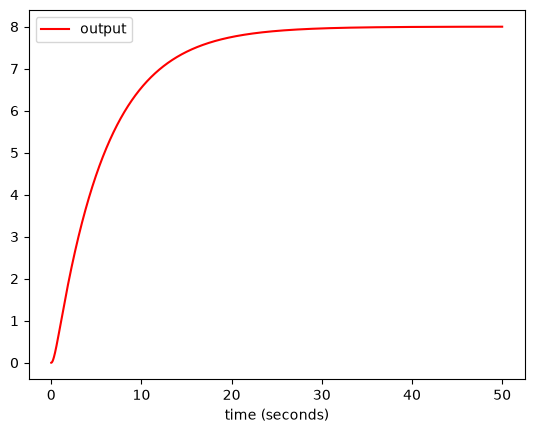

In [1]:

import arslabrobotics as ar

dp = ar.data.DataPlotter()
dp.set_x("time (seconds)")
dp.add_y("output", "output")

A = [ [0, 1],
      [-0.5, -3] ]
B = [0, 4]
C = [1, 0]

lin_sys = ar.system.LinearDynamicSystem(A, B, C)

print(lin_sys.eig().eigenvalues)

t = ar.utils.Time(use_fake_time = True)

t.start()
while t.get() < 50:
    
    t.sleep(0.001)
    delta_t = t.elapsed()
    
    out = lin_sys.evaluate(delta_t, 1.0)
    
    dp.append_x(t.get())
    dp.append_y("output", out)

dp.plot()


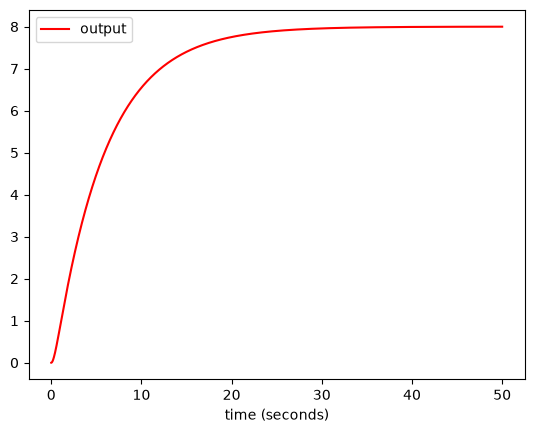

In [2]:

class ARXTest:

    def __init__(self):
        self.y = [0, 0, 0]

    def evaluate(self, delta_t, _in):
        d = (1 + 3 * delta_t + 0.5 * delta_t**2)
        
        a1 = (2 + 3 * delta_t) / d
        a2 = - 1 / d
        b0 = 4 * delta_t**2 / d
        
        out = a1 * self.y[1] + a2 * self.y[2] + b0 * _in
        
        self.y[0] = out
        # move "y"
        # self.y[0] --> self.y[1]
        # self.y[1] --> self.y[2]
        self.y[1:] = self.y[:2]
        return out

dp = ar.data.DataPlotter()
dp.set_x("time (seconds)")
dp.add_y("output", "output")

lin_sys = ARXTest()

t = ar.utils.Time(use_fake_time = True)

t.start()
while t.get() < 50:
    
    t.sleep(0.001)
    delta_t = t.elapsed()
    
    out = lin_sys.evaluate(delta_t, 1.0)
    
    dp.append_x(t.get())
    dp.append_y("output", out)

dp.plot()
